# Home Credit Default Risk — Improved Tutorial v2.0 (local, HGB-A+HGB-B blend, CSV-writer fix)

**Goal:** improve on `tutorial.ipynb` and `tutorial_improved_v1_4.ipynb` with richer v2 features + a diverse 2-model HGB blend, while fixing the CSV writer so the submission can never trigger `ParserError: Expected 1 fields in line 4, saw 2`.

**Citations (MUST_FOLLOW_RULES.md §4):**
- `tutorial.ipynb` (official competition tutorial): `Path.cwd()/"input"` local loading pattern, EDA-first workflow, submission-format validation concept.
- `tutorial_improved_v1_4.ipynb`: `add_features` base engineering (ratio/EXT/bureau/family/missing), in-fold frequency + smoothed (60) target encoding, median-impute-with-indicators, `StratifiedKFold(5)` loop, HGB-A hyperparameters, OOF grid-search + fold-averaged blending pattern.
- v2.0 additions (this notebook): `LOG_AMT_*` / `ANNUITY_CREDIT_RATE` / `INCOME_PER_CHILD` / `OWN_CAR_*` / `ORG_IS_XNA` / `RATING_POP_INTERACT`, diverse HGB-B, A+B blend, and the hardened CSV writer.

**Compliance (MUST_FOLLOW_RULES.md):** only `input/train.csv` + `input/test.csv` (no external data); no hand-labeling/manual overrides — all test predictions come from trained models; EDA is analysis-only and never becomes a prediction rule; seeds = 42 everywhere (`numpy`, `random`, `StratifiedKFold`, both HGBs); no unmeasured scores are claimed — only OOF AUCs actually computed in this run are reported.

**CSV fix context:** the scoring platform rejected an upload with `pandas.errors.ParserError: Expected 1 fields in line 4, saw 2`, which indicates the wrong file (likely the `.ipynb` JSON) was uploaded. The writer is hardened anyway: `to_csv(..., index=False, lineterminator="\n", encoding="utf-8")` (Unix newlines) + immediate pandas re-read with schema/row/ID/NaN/range asserts.


In [1]:
import os
import random
import warnings
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
warnings.filterwarnings("ignore")
# Citations: import/seed pattern follows tutorial.ipynb + tutorial_improved_v1_4.ipynb
SEED = 42
N_SPLITS = 5
SMOOTHING = 60
np.random.seed(SEED)
random.seed(SEED)
# pandas 3 note: categorical columns are hardcoded (robust to str/object dtype changes)
CAT8 = ["NAME_CONTRACT_TYPE", "CODE_GENDER", "NAME_INCOME_TYPE",
        "NAME_EDUCATION_TYPE", "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE",
        "OCCUPATION_TYPE", "ORGANIZATION_TYPE"]
print("pandas", pd.__version__, "| sklearn", __import__("sklearn").__version__)
print("CAT8 =", CAT8)


pandas 3.0.6 | sklearn 1.9.1
CAT8 = ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']


In [2]:
# Local-only paths (no Drive/Colab mount). Follows tutorial.ipynb Path.cwd()/"input" pattern.
current_dir = Path.cwd()
input_dir = current_dir / "input"
train_file = input_dir / "train.csv"
test_file = input_dir / "test.csv"
sample_sub_file = input_dir / "sample_submission.csv"
assert train_file.exists(), f"missing {train_file}"
assert test_file.exists(), f"missing {test_file}"
assert sample_sub_file.exists(), f"missing {sample_sub_file}"
train_raw = pd.read_csv(train_file)
test_raw = pd.read_csv(test_file)
sample_sub = pd.read_csv(sample_sub_file)
print("train:", train_raw.shape, "| test:", test_raw.shape, "| sample_sub:", sample_sub.shape)
assert "TARGET" in train_raw.columns and "TARGET" not in test_raw.columns
assert list(sample_sub.columns) == ["SK_ID_CURR", "TARGET"]
assert sample_sub["SK_ID_CURR"].equals(test_raw["SK_ID_CURR"])
assert len(test_raw) == 61500, len(test_raw)
y = train_raw["TARGET"].astype(int)
X_raw = train_raw.drop(columns="TARGET")
X_test_raw = test_raw.copy()
print("TARGET mean (imbalance):", float(y.mean()))
print(train_raw.dtypes.value_counts())


train: (171202, 34) | test: (61500, 33) | sample_sub: (61500, 2)
TARGET mean (imbalance): 0.08072919708881905
float64    16
int64      10
str         8
Name: count, dtype: int64


Top-15 missing fractions:
EXT_SOURCE_1                  0.694665
OWN_CAR_AGE                   0.659992
EXT_SOURCE_3                  0.318840
AMT_REQ_CREDIT_BUREAU_MON     0.135022
AMT_REQ_CREDIT_BUREAU_QRT     0.135022
AMT_REQ_CREDIT_BUREAU_HOUR    0.135022
AMT_REQ_CREDIT_BUREAU_YEAR    0.135022
EXT_SOURCE_2                  0.002155
CNT_FAM_MEMBERS               0.000012
SK_ID_CURR                    0.000000
NAME_CONTRACT_TYPE            0.000000
CODE_GENDER                   0.000000
AMT_INCOME_TOTAL              0.000000
CNT_CHILDREN                  0.000000
AMT_ANNUITY                   0.000000


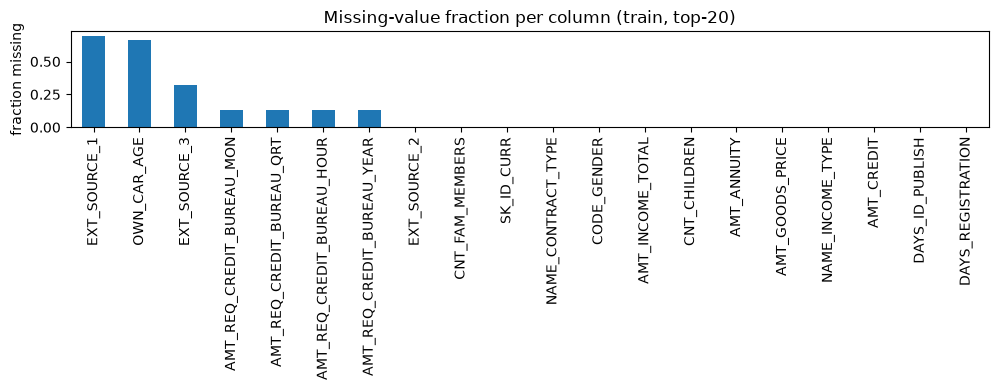


TARGET value counts:
TARGET
0    157381
1     13821
positive rate: 0.08072919708881905


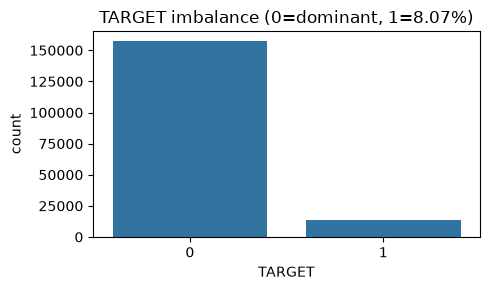


DAYS_EMPLOYED==365243: train 18.0477% | test 17.1789%
train counts: 30898 / 171202


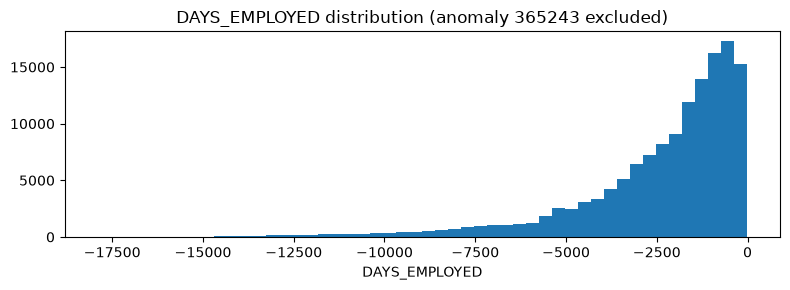

In [3]:
# EDA is analysis-only (never a prediction rule) — per MUST_FOLLOW_RULES.md §2.
# --- Missing-value bar ---
miss = train_raw.isna().mean().sort_values(ascending=False)
print("Top-15 missing fractions:")
print(miss.head(15).to_string())
plt.figure(figsize=(10, 4))
miss.head(20).plot(kind="bar")
plt.title("Missing-value fraction per column (train, top-20)")
plt.ylabel("fraction missing")
plt.tight_layout()
plt.show()
# --- TARGET imbalance ---
print("\nTARGET value counts:")
print(y.value_counts().to_string())
print("positive rate:", float(y.mean()))
plt.figure(figsize=(5, 3))
sns.countplot(x=y)
plt.title("TARGET imbalance (0=dominant, 1=%.2f%%)" % (100 * float(y.mean())))
plt.tight_layout()
plt.show()
# --- DAYS_EMPLOYED 365243 anomaly check ---
anom_tr = (train_raw["DAYS_EMPLOYED"] == 365243).mean()
anom_te = (test_raw["DAYS_EMPLOYED"] == 365243).mean()
print(f"\nDAYS_EMPLOYED==365243: train {anom_tr:.4%} | test {anom_te:.4%}")
print("train counts:", (train_raw["DAYS_EMPLOYED"] == 365243).sum(), "/", len(train_raw))
plt.figure(figsize=(8, 3))
plt.hist(train_raw.loc[train_raw["DAYS_EMPLOYED"] != 365243, "DAYS_EMPLOYED"], bins=50)
plt.title("DAYS_EMPLOYED distribution (anomaly 365243 excluded)")
plt.xlabel("DAYS_EMPLOYED")
plt.tight_layout()
plt.show()


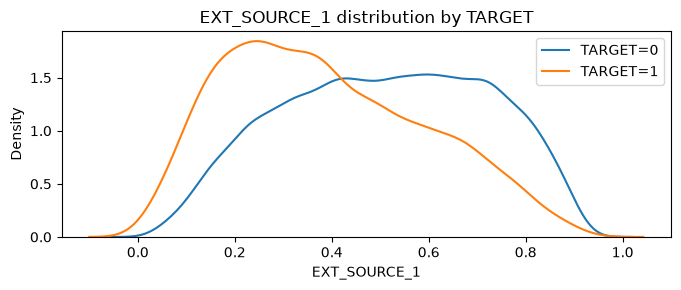

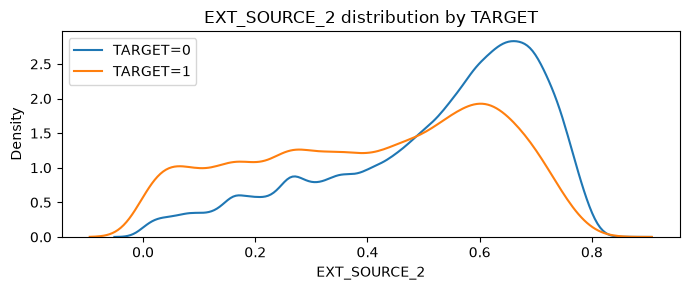

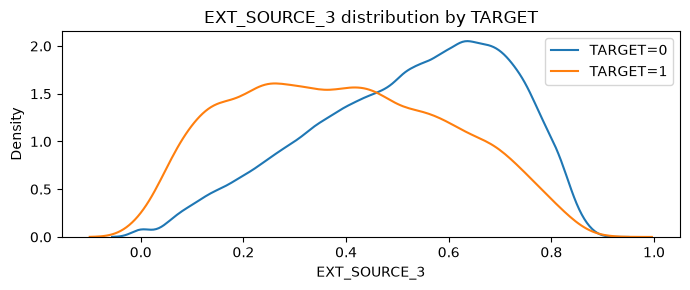

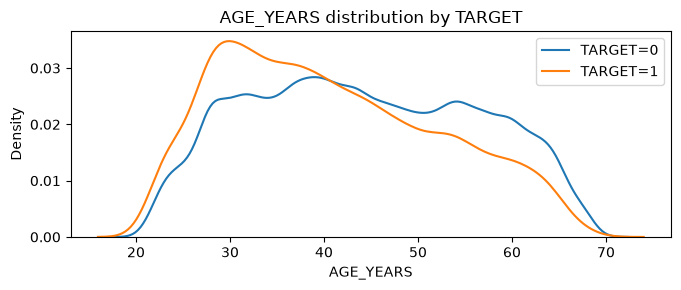

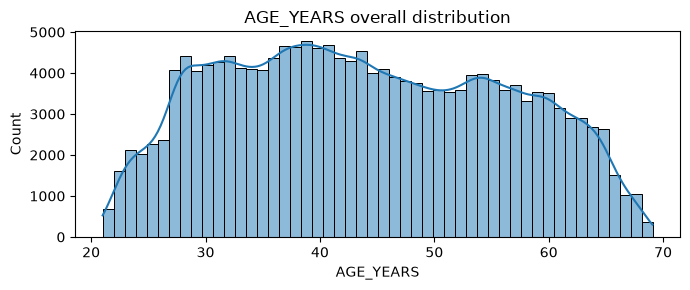

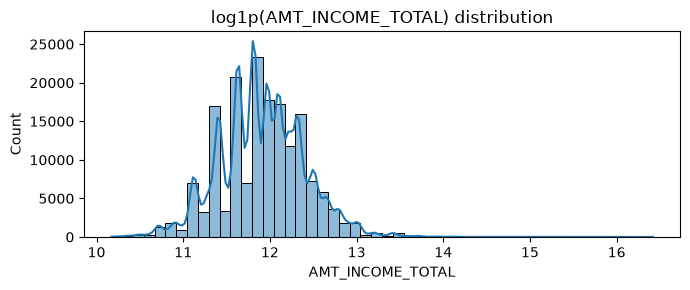

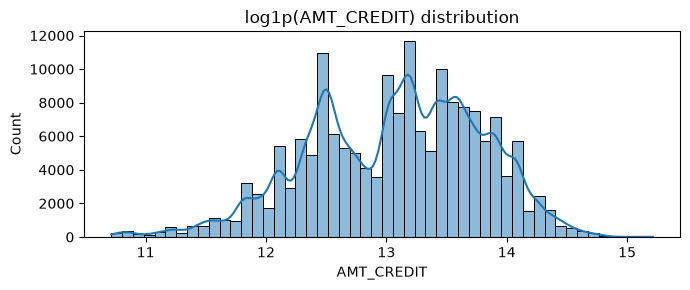

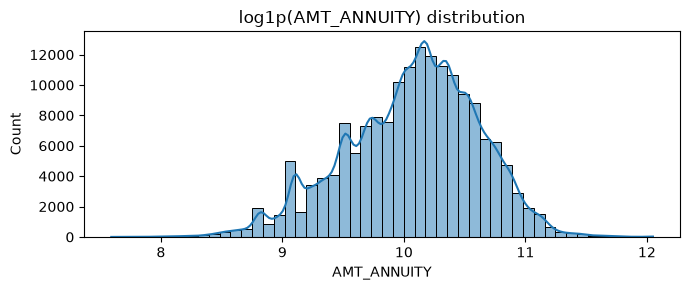

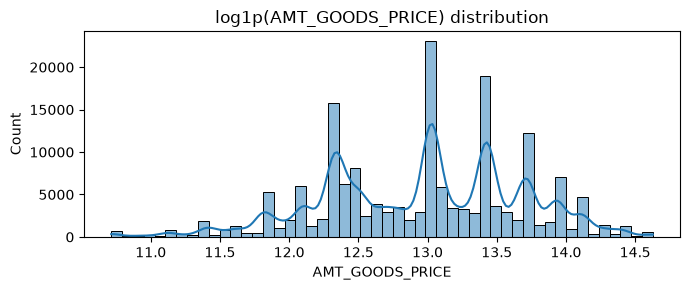

In [4]:
# EXT_SOURCE distributions by TARGET + AGE_YEARS + log AMT dists (analysis only)
train_plot = train_raw.copy()
train_plot["AGE_YEARS"] = -train_plot["DAYS_BIRTH"] / 365.25
for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
    plt.figure(figsize=(7, 3))
    for tgt, lab in [(0, "TARGET=0"), (1, "TARGET=1")]:
        sns.kdeplot(train_plot.loc[train_plot["TARGET"] == tgt, c].dropna(), label=lab)
    plt.title(f"{c} distribution by TARGET")
    plt.legend()
    plt.tight_layout()
    plt.show()
plt.figure(figsize=(7, 3))
for tgt, lab in [(0, "TARGET=0"), (1, "TARGET=1")]:
    sns.kdeplot(train_plot.loc[train_plot["TARGET"] == tgt, "AGE_YEARS"].dropna(), label=lab)
plt.title("AGE_YEARS distribution by TARGET")
plt.legend()
plt.tight_layout()
plt.show()
plt.figure(figsize=(7, 3))
sns.histplot(train_plot["AGE_YEARS"].dropna(), bins=50, kde=True)
plt.title("AGE_YEARS overall distribution")
plt.tight_layout()
plt.show()
for c in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]:
    plt.figure(figsize=(7, 3))
    sns.histplot(np.log1p(train_plot[c].clip(lower=0).dropna()), bins=50, kde=True)
    plt.title(f"log1p({c}) distribution")
    plt.tight_layout()
    plt.show()



CODE_GENDER default rates:
CODE_GENDER
M      0.101280
F      0.070023
XNA    0.000000


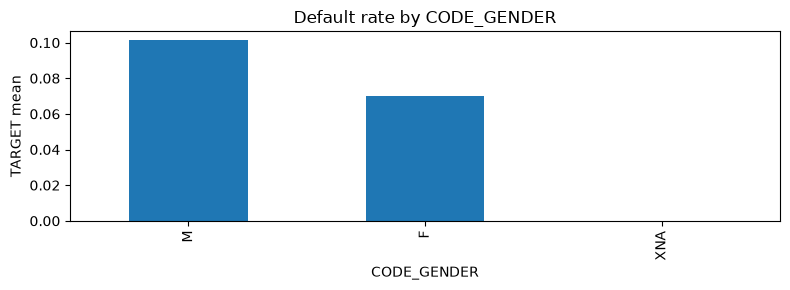


NAME_CONTRACT_TYPE default rates:
NAME_CONTRACT_TYPE
Cash loans         0.083368
Revolving loans    0.055508


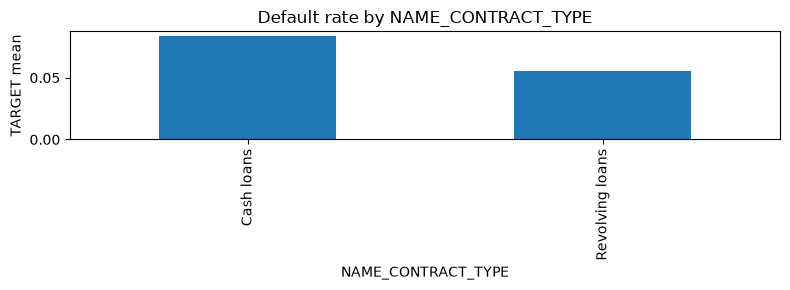


NAME_INCOME_TYPE default rates:
NAME_INCOME_TYPE
Maternity leave         0.333333
Unemployed              0.200000
Working                 0.095482
Commercial associate    0.075212
State servant           0.058882
Pensioner               0.054184
Businessman             0.000000
Student                 0.000000


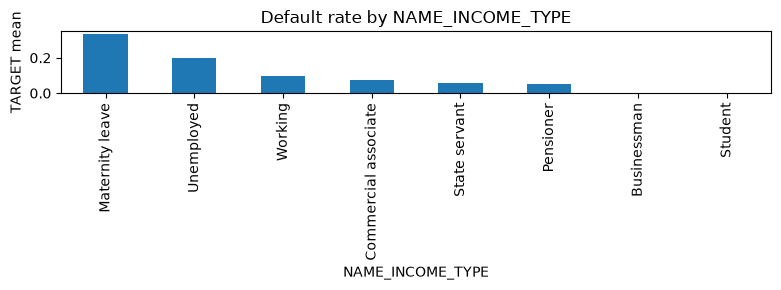


NAME_EDUCATION_TYPE default rates:
NAME_EDUCATION_TYPE
Lower secondary                  0.110642
Secondary / secondary special    0.089218
Incomplete higher                0.087200
Higher education                 0.053692
Academic degree                  0.009901


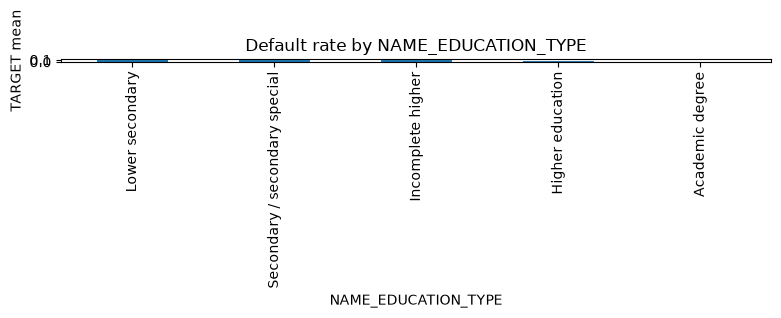


NAME_FAMILY_STATUS default rates:
NAME_FAMILY_STATUS
Civil marriage          0.098727
Single / not married    0.098556
Separated               0.082727
Married                 0.075565
Widow                   0.057529
Unknown                 0.000000


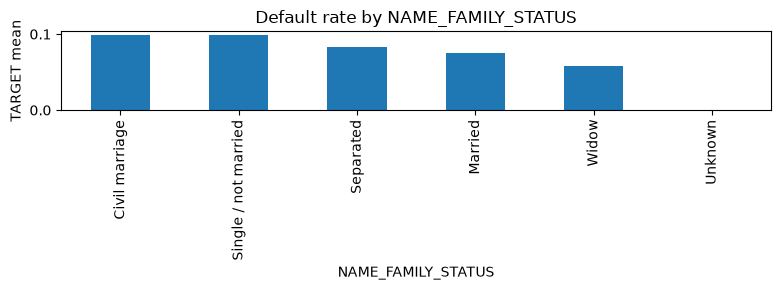


NAME_HOUSING_TYPE default rates:
NAME_HOUSING_TYPE
Rented apartment       0.129481
With parents           0.117996
Co-op apartment        0.085484
Municipal apartment    0.083534
House / apartment      0.077839
Office apartment       0.065097


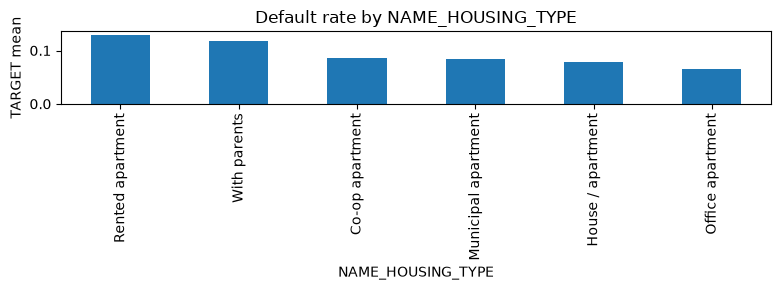


OCCUPATION_TYPE default rates:
OCCUPATION_TYPE
Low-skill Laborers       0.162349
Waiters/barmen staff     0.128514
Drivers                  0.117357
Security staff           0.109542
Laborers                 0.103994
Cooking staff            0.103788
Sales staff              0.096386
Cleaning staff           0.094663
Secretaries              0.082677
Realty agents            0.074519
IT staff                 0.071895
HR staff                 0.071197
Private service staff    0.068634
Medicine staff           0.066400
Other                    0.065532
Core staff               0.063585
Managers                 0.061240
High skill tech staff    0.060141
Accountants              0.046131


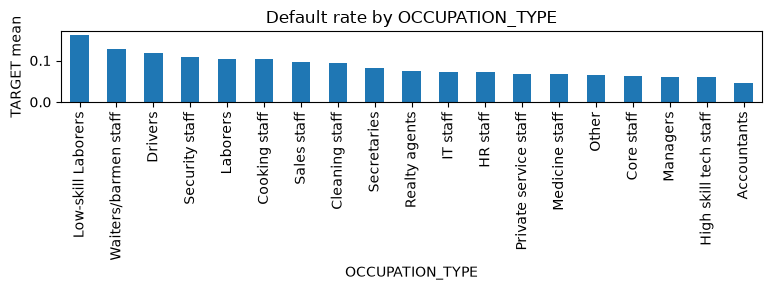


ORGANIZATION_TYPE top-10 default rates:
ORGANIZATION_TYPE
Self-employed             0.100984
Trade: type 7             0.095249
Business Entity Type 3    0.093614
Business Entity Type 2    0.087456
Other                     0.077545
Government                0.071491
Kindergarten              0.069581
Medicine                  0.066008
School                    0.059707
XNA                       0.054243


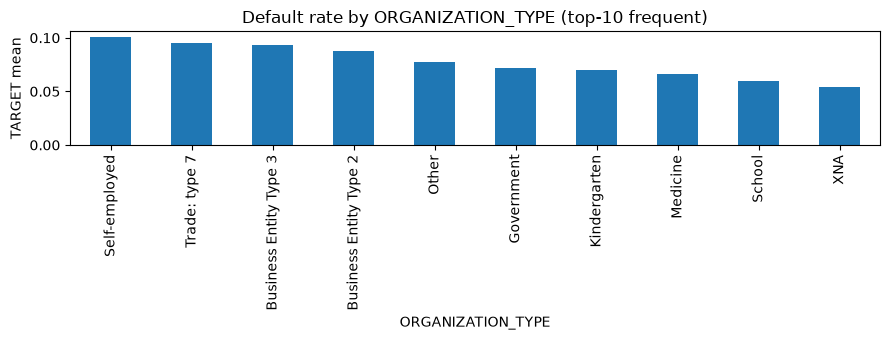

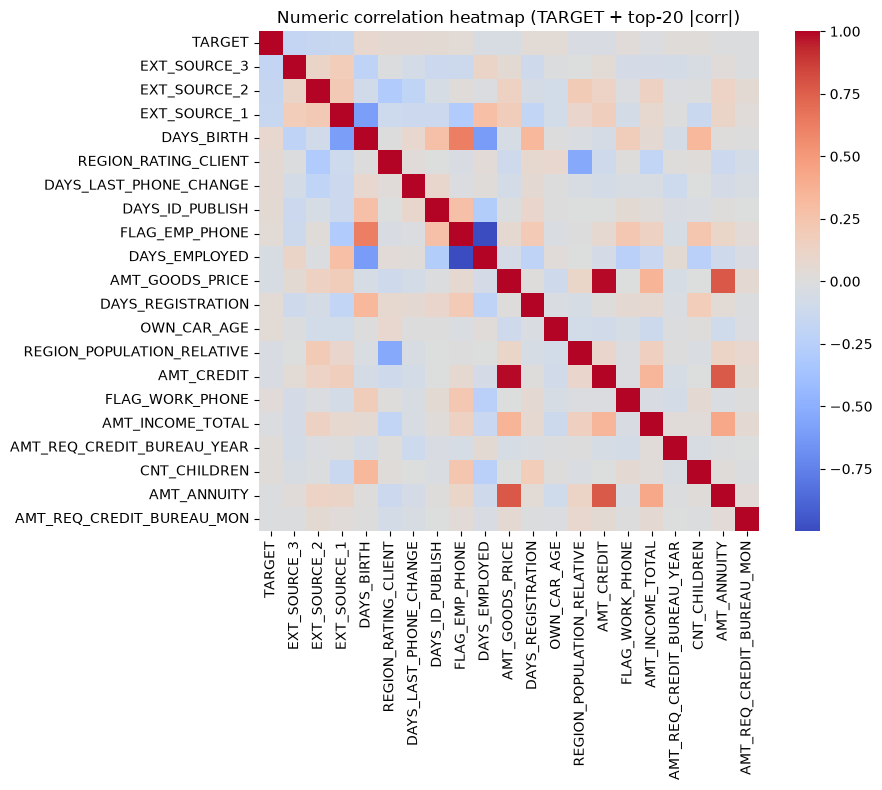

heatmap columns: ['TARGET', 'EXT_SOURCE_3', 'EXT_SOURCE_2', 'EXT_SOURCE_1', 'DAYS_BIRTH', 'REGION_RATING_CLIENT', 'DAYS_LAST_PHONE_CHANGE', 'DAYS_ID_PUBLISH', 'FLAG_EMP_PHONE', 'DAYS_EMPLOYED', 'AMT_GOODS_PRICE', 'DAYS_REGISTRATION', 'OWN_CAR_AGE', 'REGION_POPULATION_RELATIVE', 'AMT_CREDIT', 'FLAG_WORK_PHONE', 'AMT_INCOME_TOTAL', 'AMT_REQ_CREDIT_BUREAU_YEAR', 'CNT_CHILDREN', 'AMT_ANNUITY', 'AMT_REQ_CREDIT_BUREAU_MON']


In [5]:
# Categorical default-rate bars (incl. ORGANIZATION_TYPE top-10) + numeric correlation heatmap
for c in ["CODE_GENDER", "NAME_CONTRACT_TYPE", "NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE",
          "NAME_FAMILY_STATUS", "NAME_HOUSING_TYPE", "OCCUPATION_TYPE"]:
    dr = train_raw.groupby(c)["TARGET"].mean().sort_values(ascending=False)
    print(f"\n{c} default rates:")
    print(dr.to_string())
    plt.figure(figsize=(8, 3))
    dr.plot(kind="bar")
    plt.title(f"Default rate by {c}")
    plt.ylabel("TARGET mean")
    plt.tight_layout()
    plt.show()
# ORGANIZATION_TYPE top-10 by frequency
top10 = train_raw["ORGANIZATION_TYPE"].value_counts().head(10).index
sub = train_raw[train_raw["ORGANIZATION_TYPE"].isin(top10)]
dr10 = sub.groupby("ORGANIZATION_TYPE")["TARGET"].mean().sort_values(ascending=False)
print("\nORGANIZATION_TYPE top-10 default rates:")
print(dr10.to_string())
plt.figure(figsize=(9, 3.5))
dr10.plot(kind="bar")
plt.title("Default rate by ORGANIZATION_TYPE (top-10 frequent)")
plt.ylabel("TARGET mean")
plt.tight_layout()
plt.show()
# Numeric correlation heatmap
num = train_raw.select_dtypes(include=np.number)
# keep a readable subset: TARGET + top-20 numeric by abs corr with TARGET
corr_with_t = num.corr(numeric_only=True)["TARGET"].drop("TARGET").abs().sort_values(ascending=False)
keep = ["TARGET"] + corr_with_t.head(20).index.tolist()
plt.figure(figsize=(10, 8))
sns.heatmap(num[keep].corr(numeric_only=True), cmap="coolwarm", center=0, square=True)
plt.title("Numeric correlation heatmap (TARGET + top-20 |corr|)")
plt.tight_layout()
plt.show()
print("heatmap columns:", keep)


In [6]:
# add_features_v2: all v1.4 ratio/EXT/bureau/family/missing features (from tutorial_improved_v1_4.ipynb)
# PLUS LOG_AMT_* (log1p), ANNUITY_CREDIT_RATE, INCOME_PER_CHILD, OWN_CAR_MISSING + OWN_CAR_DECADE,
# ORG_IS_XNA, RATING_POP_INTERACT, inf->NaN. Applied identically to train/test.
def safe_divide(a, b):
    return a / b.replace(0, np.nan)

def add_features_v2(df):
    df = df.copy()
    # --- v1.4 base: DAYS_EMPLOYED anomaly -> NaN + flag ---
    if "DAYS_EMPLOYED" in df.columns:
        df["DAYS_EMPLOYED_ANOM"] = (df["DAYS_EMPLOYED"] == 365243).astype("int8")
        df.loc[df["DAYS_EMPLOYED"] == 365243, "DAYS_EMPLOYED"] = np.nan
    if "DAYS_BIRTH" in df.columns:
        df["AGE_YEARS"] = -df["DAYS_BIRTH"] / 365.25
    if "DAYS_EMPLOYED" in df.columns:
        df["EMPLOYED_YEARS"] = -df["DAYS_EMPLOYED"] / 365.25
    if {"DAYS_BIRTH", "DAYS_EMPLOYED"}.issubset(df.columns):
        df["EMPLOYED_AGE_RATIO"] = safe_divide(-df["DAYS_EMPLOYED"], -df["DAYS_BIRTH"])
    if {"DAYS_REGISTRATION", "DAYS_BIRTH"}.issubset(df.columns):
        df["REGISTRATION_AGE_RATIO"] = safe_divide(-df["DAYS_REGISTRATION"], -df["DAYS_BIRTH"])
    if "DAYS_REGISTRATION" in df.columns:
        df["REGISTRATION_YEARS"] = -df["DAYS_REGISTRATION"] / 365.25
    if "DAYS_ID_PUBLISH" in df.columns:
        df["ID_DOCUMENT_YEARS"] = -df["DAYS_ID_PUBLISH"] / 365.25
    if "DAYS_LAST_PHONE_CHANGE" in df.columns:
        df["PHONE_CHANGE_YEARS"] = -df["DAYS_LAST_PHONE_CHANGE"] / 365.25
    if {"AMT_CREDIT", "AMT_INCOME_TOTAL"}.issubset(df.columns):
        df["CREDIT_INCOME_RATIO"] = safe_divide(df["AMT_CREDIT"], df["AMT_INCOME_TOTAL"])
        df["INCOME_CREDIT_RATIO"] = safe_divide(df["AMT_INCOME_TOTAL"], df["AMT_CREDIT"])
    if {"AMT_ANNUITY", "AMT_INCOME_TOTAL"}.issubset(df.columns):
        df["ANNUITY_INCOME_RATIO"] = safe_divide(df["AMT_ANNUITY"], df["AMT_INCOME_TOTAL"])
        df["INCOME_ANNUITY_RATIO"] = safe_divide(df["AMT_INCOME_TOTAL"], df["AMT_ANNUITY"])
    if {"AMT_CREDIT", "AMT_ANNUITY"}.issubset(df.columns):
        df["CREDIT_ANNUITY_RATIO"] = safe_divide(df["AMT_CREDIT"], df["AMT_ANNUITY"])
    if {"AMT_GOODS_PRICE", "AMT_CREDIT"}.issubset(df.columns):
        df["GOODS_CREDIT_RATIO"] = safe_divide(df["AMT_GOODS_PRICE"], df["AMT_CREDIT"])
        df["CREDIT_GOODS_GAP"] = df["AMT_CREDIT"] - df["AMT_GOODS_PRICE"]
    if {"AMT_INCOME_TOTAL", "CNT_FAM_MEMBERS"}.issubset(df.columns):
        df["INCOME_PER_FAMILY"] = safe_divide(df["AMT_INCOME_TOTAL"], df["CNT_FAM_MEMBERS"].clip(lower=1))
    if {"AMT_CREDIT", "CNT_FAM_MEMBERS"}.issubset(df.columns):
        df["CREDIT_PER_FAMILY"] = safe_divide(df["AMT_CREDIT"], df["CNT_FAM_MEMBERS"].clip(lower=1))
    ext = [c for c in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"] if c in df.columns]
    if ext:
        df["EXT_SOURCE_MEAN"] = df[ext].mean(axis=1)
        df["EXT_SOURCE_MEDIAN"] = df[ext].median(axis=1)
        df["EXT_SOURCE_MIN"] = df[ext].min(axis=1)
        df["EXT_SOURCE_MAX"] = df[ext].max(axis=1)
        df["EXT_SOURCE_RANGE"] = df[ext].max(axis=1) - df[ext].min(axis=1)
        df["EXT_SOURCE_STD"] = df[ext].std(axis=1)
        df["EXT_SOURCE_MISSING"] = df[ext].isna().sum(axis=1)
        for c in ext:
            df[c + "_SQ"] = df[c] ** 2
            df[c + "_CUBE"] = df[c] ** 3
        for i in range(len(ext)):
            for j in range(i + 1, len(ext)):
                a, b = ext[i], ext[j]
                df[a + "_" + b + "_PROD"] = df[a] * df[b]
                df[a + "_" + b + "_DIFF"] = df[a] - df[b]
                df[a + "_" + b + "_ABS_DIFF"] = (df[a] - df[b]).abs()
                df[a + "_" + b + "_RATIO"] = safe_divide(df[a], df[b])
    bureau = [c for c in df.columns if c.startswith("AMT_REQ_CREDIT_BUREAU_")]
    if bureau:
        df["BUREAU_REQUEST_TOTAL"] = df[bureau].sum(axis=1, min_count=1)
        df["BUREAU_REQUEST_MEAN"] = df[bureau].mean(axis=1)
        df["BUREAU_REQUEST_MAX"] = df[bureau].max(axis=1)
        df["BUREAU_REQUEST_MISSING"] = df[bureau].isna().sum(axis=1)
    if {"CNT_CHILDREN", "CNT_FAM_MEMBERS"}.issubset(df.columns):
        df["CHILDREN_FAMILY_RATIO"] = safe_divide(df["CNT_CHILDREN"], df["CNT_FAM_MEMBERS"].clip(lower=1))
        df["ADULTS_IN_FAMILY"] = df["CNT_FAM_MEMBERS"] - df["CNT_CHILDREN"]
    contact = [c for c in ["FLAG_MOBIL", "FLAG_EMP_PHONE", "FLAG_WORK_PHONE",
                           "FLAG_CONT_MOBILE", "FLAG_PHONE", "FLAG_EMAIL"] if c in df.columns]
    if contact:
        df["CONTACT_FLAG_SUM"] = df[contact].sum(axis=1)
    df["TOTAL_MISSING"] = df.isna().sum(axis=1)
    df["MISSING_RATIO"] = df.isna().mean(axis=1)
    # --- v2.0 additions ---
    for col, new in [("AMT_INCOME_TOTAL", "LOG_AMT_INCOME_TOTAL"),
                     ("AMT_CREDIT", "LOG_AMT_CREDIT"),
                     ("AMT_ANNUITY", "LOG_AMT_ANNUITY"),
                     ("AMT_GOODS_PRICE", "LOG_AMT_GOODS_PRICE")]:
        if col in df.columns:
            df[new] = np.log1p(df[col].clip(lower=0))
    if {"AMT_ANNUITY", "AMT_CREDIT"}.issubset(df.columns):
        df["ANNUITY_CREDIT_RATE"] = safe_divide(df["AMT_ANNUITY"], df["AMT_CREDIT"])
    if {"AMT_INCOME_TOTAL", "CNT_CHILDREN"}.issubset(df.columns):
        df["INCOME_PER_CHILD"] = safe_divide(df["AMT_INCOME_TOTAL"], (df["CNT_CHILDREN"] + 1))
    if "OWN_CAR_AGE" in df.columns:
        df["OWN_CAR_MISSING"] = df["OWN_CAR_AGE"].isna().astype("int8")
        df["OWN_CAR_DECADE"] = df["OWN_CAR_AGE"] / 10.0
    if "ORGANIZATION_TYPE" in df.columns:
        df["ORG_IS_XNA"] = (df["ORGANIZATION_TYPE"] == "XNA").astype("int8")
    if {"REGION_RATING_CLIENT", "REGION_POPULATION_RELATIVE"}.issubset(df.columns):
        df["RATING_POP_INTERACT"] = df["REGION_RATING_CLIENT"] * df["REGION_POPULATION_RELATIVE"]
    df = df.replace([np.inf, -np.inf], np.nan)
    return df

X = add_features_v2(X_raw)
X_test = add_features_v2(X_test_raw).reindex(columns=X.columns, fill_value=np.nan)
print("X:", X.shape, "| X_test:", X_test.shape)
assert list(X.columns) == list(X_test.columns), "train/test column mismatch"
assert X.shape[0] == len(train_raw) and X_test.shape[0] == 61500
new_v2 = ["LOG_AMT_INCOME_TOTAL", "LOG_AMT_CREDIT", "LOG_AMT_ANNUITY", "LOG_AMT_GOODS_PRICE",
          "ANNUITY_CREDIT_RATE", "INCOME_PER_CHILD", "OWN_CAR_MISSING", "OWN_CAR_DECADE",
          "ORG_IS_XNA", "RATING_POP_INTERACT"]
for c in new_v2:
    assert c in X.columns, f"missing {c}"
print("v2 features present:", new_v2)
print("n_numeric:", len([c for c in X.columns if c not in CAT8]), "| n_cat8:", len([c for c in CAT8 if c in X.columns]))


X: (171202, 94) | X_test: (61500, 94)
v2 features present: ['LOG_AMT_INCOME_TOTAL', 'LOG_AMT_CREDIT', 'LOG_AMT_ANNUITY', 'LOG_AMT_GOODS_PRICE', 'ANNUITY_CREDIT_RATE', 'INCOME_PER_CHILD', 'OWN_CAR_MISSING', 'OWN_CAR_DECADE', 'ORG_IS_XNA', 'RATING_POP_INTERACT']
n_numeric: 86 | n_cat8: 8


In [7]:
# In-fold frequency + smoothed target encoding (smoothing=60) for the 8 hardcoded
# categoricals — fit on train folds only. Pattern from tutorial_improved_v1_4.ipynb.
# Hardcoded CAT8 keeps this robust to pandas 3 str/object dtype changes.
def frequency_map(train_df, other_df, cols):
    out = other_df.copy()
    for c in cols:
        m = train_df[c].value_counts(dropna=False, normalize=True)
        out[c + "__FREQ"] = other_df[c].map(m).fillna(0.0)
    return out

def target_map(train_df, y_train, other_df, cols, smoothing=60):
    out = other_df.copy()
    gm = float(np.mean(y_train))
    for c in cols:
        tmp = pd.DataFrame({"x": train_df[c].astype(object).values, "y": np.asarray(y_train)})
        st = tmp.groupby("x", dropna=False)["y"].agg(["mean", "count"])
        sm = (st["mean"] * st["count"] + gm * smoothing) / (st["count"] + smoothing)
        out[c + "__TE"] = other_df[c].map(sm).fillna(gm).astype(float)
    return out

cat_cols = [c for c in CAT8 if c in X.columns]
print("encoding categoricals:", cat_cols)
assert len(cat_cols) == 8, cat_cols
print("smoothing:", SMOOTHING)


encoding categoricals: ['NAME_CONTRACT_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE']
smoothing: 60


In [8]:
# StratifiedKFold(5, shuffle, seed 42); HGB-A + diverse HGB-B; median imputation
# with indicators (fit on train folds only); per-fold AUC prints + OOF AUCs.
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
oof_a = np.zeros(len(X))
oof_b = np.zeros(len(X))
test_a = np.zeros(len(X_test))
test_b = np.zeros(len(X_test))
fold_a, fold_b = [], []
for fold, (tr_idx, va_idx) in enumerate(skf.split(X, y), 1):
    X_tr, X_va = X.iloc[tr_idx].copy(), X.iloc[va_idx].copy()
    y_tr, y_va = y.iloc[tr_idx], y.iloc[va_idx]
    X_te = X_test.copy()
    tr_num = X_tr.drop(columns=cat_cols).copy()
    va_num = X_va.drop(columns=cat_cols).copy()
    te_num = X_te.drop(columns=cat_cols).copy()
    tr_e = frequency_map(X_tr, X_tr, cat_cols)
    va_e = frequency_map(X_tr, X_va, cat_cols)
    te_e = frequency_map(X_tr, X_te, cat_cols)
    tr_e = target_map(X_tr, y_tr, tr_e, cat_cols, smoothing=SMOOTHING)
    va_e = target_map(X_tr, y_tr, va_e, cat_cols, smoothing=SMOOTHING)
    te_e = target_map(X_tr, y_tr, te_e, cat_cols, smoothing=SMOOTHING)
    add_c = [c for c in tr_e.columns if c.endswith("__FREQ") or c.endswith("__TE")]
    tr_num = pd.concat([tr_num, tr_e[add_c]], axis=1)
    va_num = pd.concat([va_num, va_e[add_c]], axis=1)
    te_num = pd.concat([te_num, te_e[add_c]], axis=1)
    imp = SimpleImputer(strategy="median", add_indicator=True)
    tr_num = imp.fit_transform(tr_num)
    va_num = imp.transform(va_num)
    te_num = imp.transform(te_num)
    mA = HistGradientBoostingClassifier(learning_rate=0.035, max_iter=700,
                                        max_leaf_nodes=31, min_samples_leaf=80,
                                        l2_regularization=2.0, random_state=SEED)
    mB = HistGradientBoostingClassifier(learning_rate=0.06, max_iter=500,
                                        max_leaf_nodes=63, min_samples_leaf=40,
                                        l2_regularization=0.5, random_state=SEED)
    mA.fit(tr_num, y_tr)
    mB.fit(tr_num, y_tr)
    pa = mA.predict_proba(va_num)[:, 1]
    pb = mB.predict_proba(va_num)[:, 1]
    oof_a[va_idx] = pa
    oof_b[va_idx] = pb
    test_a += mA.predict_proba(te_num)[:, 1] / N_SPLITS
    test_b += mB.predict_proba(te_num)[:, 1] / N_SPLITS
    sa, sb = roc_auc_score(y_va, pa), roc_auc_score(y_va, pb)
    fold_a.append(sa)
    fold_b.append(sb)
    print(f"fold {fold}: HGB-A={sa:.6f} HGB-B={sb:.6f}")
auc_a = roc_auc_score(y, oof_a)
auc_b = roc_auc_score(y, oof_b)
print("HGB-A per-fold:", [round(s, 6) for s in fold_a])
print("HGB-B per-fold:", [round(s, 6) for s in fold_b])
print(f"HGB-A OOF AUC={auc_a:.6f}")
print(f"HGB-B OOF AUC={auc_b:.6f}")


fold 1: HGB-A=0.755131 HGB-B=0.752639


fold 2: HGB-A=0.756446 HGB-B=0.754317


fold 3: HGB-A=0.761442 HGB-B=0.758925


fold 4: HGB-A=0.753367 HGB-B=0.750217


fold 5: HGB-A=0.757281 HGB-B=0.755231


HGB-A per-fold: [0.755131, 0.756446, 0.761442, 0.753367, 0.757281]
HGB-B per-fold: [0.752639, 0.754317, 0.758925, 0.750217, 0.755231]
HGB-A OOF AUC=0.756665
HGB-B OOF AUC=0.754156


In [9]:
# OOF weight grid search for the A+B blend (step 0.05, OOF-selected)
best_score = max(auc_a, auc_b)
best_w = {"hgb_a": 1.0, "hgb_b": 0.0} if auc_a >= auc_b else {"hgb_a": 0.0, "hgb_b": 1.0}
for w in np.arange(0, 1.001, 0.05):
    p = w * oof_a + (1 - w) * oof_b
    s = roc_auc_score(y, p)
    if s > best_score:
        best_score = s
        best_w = {"hgb_a": float(w), "hgb_b": float(1 - w)}
print("best weights:", best_w)
print(f"blend OOF AUC={best_score:.6f}")
final_pred = best_w["hgb_a"] * test_a + best_w["hgb_b"] * test_b
final_pred = np.clip(final_pred, 0, 1)
print("final_pred describe:")
print(pd.Series(final_pred).describe().to_string())


best weights: {'hgb_a': 0.8, 'hgb_b': 0.19999999999999996}
blend OOF AUC=0.756815
final_pred describe:
count    61500.000000
mean         0.091264
std          0.087559
min          0.005790
25%          0.032444
50%          0.060391
75%          0.116998
max          0.698502


In [10]:
# THE FIX: Unix newlines + utf-8 + immediate re-read validation.
# The ParserError (Expected 1 fields in line 4, saw 2) indicates the wrong file
# (.ipynb JSON) was uploaded; this writer is hardened regardless.
output_dir = current_dir / "output"
output_dir.mkdir(exist_ok=True)
output_file = output_dir / "submission_improved_v2_0.csv"
submission = sample_sub.copy()
submission["TARGET"] = final_pred
assert submission["SK_ID_CURR"].equals(test_raw["SK_ID_CURR"])
submission.to_csv(output_file, index=False, lineterminator="\n", encoding="utf-8")
print("wrote:", output_file)
# Re-read + assert exact schema
chk = pd.read_csv(output_file)
assert list(chk.columns) == ["SK_ID_CURR", "TARGET"], list(chk.columns)
assert len(chk) == 61500, len(chk)
assert chk["SK_ID_CURR"].equals(test_raw["SK_ID_CURR"]), "ID mismatch"
assert chk["TARGET"].isna().sum() == 0, "NaN in TARGET"
assert ((chk["TARGET"] >= 0) & (chk["TARGET"] <= 1)).all(), "probs out of [0,1]"
raw = open(output_file, "rb").read()
assert b"\r" not in raw, "CR found — file must use Unix newlines"
assert raw.split(b"\n")[0].strip() == b"SK_ID_CURR,TARGET", raw[:50]
print("CSV validation passed: columns [SK_ID_CURR,TARGET], 61500 rows, IDs match, no NaN, probs in [0,1], Unix newlines.")
print(chk.head().to_string(index=False))
print(chk["TARGET"].describe().to_string())


wrote: C:\Users\sidha\Documents\visual code\Competition\output\submission_improved_v2_0.csv


CSV validation passed: columns [SK_ID_CURR,TARGET], 61500 rows, IDs match, no NaN, probs in [0,1], Unix newlines.
 SK_ID_CURR   TARGET
     171202 0.032881
     171203 0.214676
     171204 0.153225
     171205 0.113756
     171206 0.231583
count    61500.000000
mean         0.091264
std          0.087559
min          0.005790
25%          0.032444
50%          0.060391
75%          0.116998
max          0.698502


In [11]:
# Final cell: zip ONLY the notebook (for Honors/Outstanding reproducibility upload)
import zipfile
notebook_filename = "tutorial_improved_v2_0.ipynb"
zip_filename = "tutorial_improved_v2_0.zip"
notebook_path = current_dir / notebook_filename
zip_output_path = current_dir / zip_filename
assert notebook_path.exists(), f"missing {notebook_path}"
with zipfile.ZipFile(zip_output_path, "w", zipfile.ZIP_DEFLATED) as zf:
    zf.write(notebook_path, arcname=notebook_filename)
print(f"created: {zip_output_path}")
with zipfile.ZipFile(zip_output_path, "r") as zf:
    names = zf.namelist()
    print("zip contents:", names)
    assert names == [notebook_filename], names


created: C:\Users\sidha\Documents\visual code\Competition\tutorial_improved_v2_0.zip
zip contents: ['tutorial_improved_v2_0.ipynb']
